# Style Sheet

In [1]:
import matplotlib.pyplot as plt
import numpy as np
plt.style.use(r'style_sheets/base.mplstyle')

from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
from matplotlib.font_manager import FontProperties
 
 
# SI length ladder (value of each prefix in metres), low -> high
_SI_ORDER = [("pm", 1e-12), ("nm", 1e-9), ("µm", 1e-6),
             ("mm", 1e-3), ("cm", 1e-2), ("m", 1.0)]
_SI = dict(_SI_ORDER) | {"um": 1e-6}  # accept ASCII 'um' as an alias
 
 
def _nice_125(x):
    """Snap x>0 to the nearest {1,2,5}x10^n value, measured in log space."""
    if x <= 0:
        return x
    exp = np.floor(np.log10(x))
    mantissa = x / 10.0 ** exp                       # in [1, 10)
    candidates = np.array([1.0, 2.0, 5.0, 10.0])     # 10 catches top of decade
    m = candidates[np.argmin(np.abs(np.log(candidates) - np.log(mantissa)))]
    return m * 10.0 ** exp
 
 
def _format_length(value, units, scale=True):
    """Relabel a length with the most readable SI prefix (physical size fixed)."""
    if not scale or units not in _SI:
        return f"{value:g} {units}"
    metres = value * _SI[units]
    name, fac = _SI_ORDER[0]
    for n, f in _SI_ORDER:                            # largest prefix with mantissa >= 1
        if metres >= f:
            name, fac = n, f
    return f"{metres / fac:g} {name}"
 
 
def add_scalebar(ax, dx, units="nm", length_fraction=0.1,
                 loc="lower right", color="black", box_alpha=0.0,
                 height_fraction=0.01, sep=4, pad=0.4,
                 fontsize=None, label_top=False, scale_units=True):
    """
    Add a physical scale bar to `ax`.
 
    Parameters
    ----------
    ax : matplotlib.axes.Axes
    dx : float
        Physical size of one data unit (e.g. nm per pixel).
    units : str
        Units of `dx`. Length units (pm, nm, µm/um, mm, cm, m) auto-rescale
        for the label when `scale_units` is True.
    length_fraction : float
        Target fraction f of the x-axis the bar should span; the drawn length
        is the {1,2,5}x10^n value closest (in log) to f * W * dx.
    loc : str or int
        Anchor location, e.g. 'lower right'.
    color : str
        Bar and text colour ('white' is usual on dark micrographs).
    box_alpha : float
        Background box opacity; 0 -> no frame.
    height_fraction : float
        Bar thickness as a fraction of the y-axis range.
    sep : float
        Gap (pt) between bar and label.
    pad : float
        Padding (in fontsize units) inside the anchored box.
    fontsize : float or None
    label_top : bool
        Put the label above the bar instead of below.
    scale_units : bool
        Auto-pick a readable SI prefix for the label.
 
    Returns
    -------
    AnchoredSizeBar
    """
    # axis extent in data units
    x0, x1 = ax.get_xlim()
    W = abs(x1 - x0)
 
    # target physical length -> nice value -> length back in data units
    nice = _nice_125(length_fraction * W * dx)
    size_data = nice / dx
 
    # bar thickness in data units
    y0, y1 = ax.get_ylim()
    size_vertical = height_fraction * abs(y1 - y0)
 
    label = _format_length(nice, units, scale=scale_units)
    fontprops = FontProperties(size=fontsize) if fontsize is not None else None
 
    bar = AnchoredSizeBar(
        ax.transData,
        size_data,
        label,
        loc=loc,
        pad=pad,
        sep=sep,
        color=color,
        frameon=(box_alpha > 0),
        size_vertical=size_vertical,
        label_top=label_top,
        fontproperties=fontprops,
    )
    if box_alpha > 0:                                # match box_alpha semantics
        bar.patch.set_alpha(box_alpha)
        bar.patch.set_facecolor("white")
        bar.patch.set_edgecolor("none")
 
    ax.add_artist(bar)
    return bar


from pathlib import Path

def save_fig(fig=None, path="figure", *, dpi=600, transparent=True,
             pad_inches=0.05, editable_text=False, also=None):
    """Save a Matplotlib figure as a publication-ready SVG.

    Parameters
    ----------
    fig : Figure, optional
        Figure to save. Defaults to the current figure (plt.gcf()).
    path : str or Path
        Output path. A '.svg' suffix is added if missing.
    dpi : int
        Resolution of *embedded raster layers only* (e.g. imshow images);
        vector elements are unaffected. 600 keeps micrographs crisp.
    transparent : bool
        Transparent figure/axes background (lets the SVG sit on any page color).
    pad_inches : float
        Padding around the tight bounding box, in inches.
    editable_text : bool
        If True, keep glyphs as <text> (editable in Illustrator/Inkscape,
        smaller files). Ignored when text.usetex=True, since LaTeX emits paths.
    also : str or list of str, optional
        Extra formats to write alongside the SVG, e.g. 'pdf' or ['pdf', 'png'].
    """
    fig = fig or plt.gcf()
    path = Path(path).with_suffix(".svg")
    path.parent.mkdir(parents=True, exist_ok=True)

    if editable_text and not plt.rcParams.get("text.usetex", False):
        plt.rcParams["svg.fonttype"] = "none"

    kw = dict(dpi=dpi, transparent=transparent,
              bbox_inches="tight", pad_inches=pad_inches)

    fig.savefig(path, **kw)

    if also:
        for fmt in ([also] if isinstance(also, str) else also):
            fig.savefig(path.with_suffix(f".{fmt}"), **kw)

    return path


In [3]:
import h5py
import os

class SingleParticle():
    def __init__(self, x,y,z):
        self.traj_x = x
        self.traj_y = y
        self.traj_z = z

def LoadDataset(file_name):
    '''
    Loads the h5 dataset developed by martin's TracesROi_to_z_analysis.py script.
    '''
    dataset_all = []
    # Open the file in read mode
    with h5py.File(file_name, 'r') as f:
        #print(f"Keys in the HDF5 file: {list(f.keys())}")
        
        # Iterate through keys and print their types
        for key in f.keys():
            #print(f"Object name: {key}, Object type: {type(f[key])}")
            dset = f[key] # this is a croup with N_particles which are all 'members'
            for particle_index in dset:
                #print(dset[particle_index].keys())

                # this reads in a pointer
                grp = dset[particle_index]
                # This accesses the memory directly
                curr_particle = SingleParticle(
                    grp['x'][:],
                    grp['y'][:],
                    grp['z'][:],
                    #grp['diffusion_msd'][()],
                    #grp['diffusion_confined'][()],
                    #grp['length_confined'][()]
                )
                # append the data to the dataset file
                dataset_all.append(curr_particle)

    print(f'Particles in Current Dataset: {len(dataset_all)}')
    return dataset_all

# PBS Series

In [4]:
# List of Datasets For Figure 1
# Polystyrene + PBS
PS_PBS0p1_225nm   = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p1\ClicOnLeft2\ClicOnLeft2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
PS_PBS0p01_225nm  = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p01\center2\center2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
PS_PBS0p001_225nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p001\center_2\center_2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
#PS_PBS0p001_300nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p001\center_3\center_3radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
#PS_PBS0p001_375nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p001\center_4\center_4radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")
PS_PBS0p00001_225nm = LoadDataset(r"Z:\Data\Martin\Odin_PlanarConfinement_iScat\FinalFigures\PS100_PBS_0p00001\ClicOnLeft_2\ClicOnLeft_2radial_int_50_to_120ws_8_we_26_PythonAnalysis.h5")

Particles in Current Dataset: 8
Particles in Current Dataset: 53
Particles in Current Dataset: 13
Particles in Current Dataset: 62


In [5]:
from hdr.transverse_estimation import Traj_XY_confinement_to_radius
from hdr.transverse_estimation import getMeanSquaredDisplacement
from hdr.axial_estimation import LineAnalyticalMSD
from tqdm import tqdm
from scipy.optimize import curve_fit

def GetHistFWHM(data, bins=10):
    # 1. Compute the histogram
    counts, bin_edges = np.histogram(data, bins=bins)
    
    # 2. Get the centers of the bins
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # 3. Find the maximum height of the peak
    max_idx = np.argmax(counts)
    max_val = counts[max_idx]
    half_max = max_val / 2.0
    
    # 4. Find the crossing points using interpolation 
    # Left of the peak
    hist_left = counts[:max_idx]
    bin_left = bin_centers[:max_idx]
    # Find the nearest elements to half_max
    left_idx = np.where(hist_left <= half_max)[0]
    if len(left_idx) == 0:
        return None  # Peak doesn't drop below half_max on the left
    
    # Take the index closest to the peak on the left
    x1 = np.interp(half_max, 
                   [hist_left[left_idx[-1]-1], hist_left[left_idx[-1]]], 
                   [ bin_left[left_idx[-1]-1],  bin_left[left_idx[-1]]])
    
    # Right of the peak
    hist_right = counts[max_idx:]
    bin_right = bin_centers[max_idx:]
    right_idx = np.where(hist_right <= half_max)[0]
    if len(right_idx) == 0:
        return None  # Peak doesn't drop below half_max on the right
    
    # Take the first index that drops below half_max on the right
    x2 = np.interp(half_max, [hist_right[right_idx[0]-1], hist_right[right_idx[0]]], 
                   [bin_right[right_idx[0]-1], bin_right[right_idx[0]]])
    
    # 5. Calculate FWHM
    return x2 - x1

def GetFwhmTransverseRadius(dataset, fps = 400, px_size = 55* 10**(-9), visc=1* 10**(-3), channel_height=225, distance_thresh=0):
    trajx_temp = []
    trajy_temp = []
    trajz_temp = []

    for PID in dataset:
        # get trajectory information
        trajx_temp.append(PID.traj_x)
        trajy_temp.append(PID.traj_y)
        trajz_temp.append(PID.traj_z)

    # radius xy
    RADXY, FILTXY = Traj_XY_confinement_to_radius(  trajx_temp,
                                                    trajy_temp,
                                                    fps=fps,
                                                    px_size=px_size,
                                                    visc=visc,
                                                    channel_height=channel_height,distance_thresh=distance_thresh
                                                    )
    

    radius_transverse = [RADXY[x] for x in FILTXY]
    fwhm_arr = []
    for item in tqdm(trajz_temp):
        fwhm_arr.append(GetHistFWHM(item))

    FWHM = [fwhm_arr[x] for x in FILTXY]
    return radius_transverse, FWHM

def GetRadius(dataset, fps = 400, px_size = 55* 10**(-9), visc=1* 10**(-3), channel_height=225, distance_thresh=0):
    
    radius_transverse = []
    radius_axial      = []
    trajx_temp = []
    trajy_temp = []
    trajz_temp = []

    for PID in dataset:
        # get trajectory information
        trajx_temp.append(PID.traj_x)
        trajy_temp.append(PID.traj_y)
        trajz_temp.append(PID.traj_z)

    # radius xy
    RADXY, FILTXY = Traj_XY_confinement_to_radius(  trajx_temp,
                                                    trajy_temp,
                                                    fps=fps,
                                                    px_size=px_size,
                                                    visc=visc,
                                                    channel_height=channel_height,distance_thresh=distance_thresh
                                                    )
    
    radius_transverse = [RADXY[x] for x in FILTXY]

    LAG_Axial = []
    MSD_Axial = []
    Dif_Axial = []
    Len_Axial = []
    Rad_Axial = []

    for item in tqdm(trajz_temp):
        traj_loop = np.array(item)
        traj_loop = np.reshape(traj_loop, (1, len(traj_loop)))
        msd, lag, ndim = getMeanSquaredDisplacement(traj_loop)
        MSD_Axial.append(msd[1:])
        LAG_Axial.append(lag[1:])
        # --------------------------- Get MSD --------------------------------#
        # fit MSD to line using scipy curvefit
        param, popt = curve_fit(LineAnalyticalMSD, lag[1:200], msd[1:200], (1, 100))
        
        ## get the diffusivity
        Dif_Axial.append(param[0])
        Len_Axial.append(param[1])
        Rad_Axial.append((channel_height - np.abs(param[1]))/2)

    radius_axial = [Rad_Axial[x] for x in FILTXY]
    return radius_transverse, radius_axial

def ConfinementDiffusionCorrection(D_conf, a, h, mode='parr'):
    match mode:
        case 'parr':
            h2 = h/2
            term1 = -9/16   * (a/h2)
            term2 =  1/8    * (a/h2)**3
            term3 = -45/256 * (a/h2)**4
            term4 = -1/16   * (a/h2)**5
            #lambda_inv = 1 + term1 + term2 + term3 + term4
            lambda_inv= (2/ (1 + term1 + term2 + term3 + term4) - 1);

            return D_conf  / lambda_inv 
         
        case 'perp':
            term1 = -9/8    * (a/h)
            term2 =  1/2    * (a/h)**3
            lambda_inv = 1 + term1 + term2
            return D_conf / lambda_inv
        case _:
            return 0
        

channel_height =  225 # nm
hat_r = np.arange(0, channel_height, 0.1) # 0.1 nm steps

In [ ]:
#RXY_PS100_0p1,      RZ_PS100_0p1        = GetRadius(PS_PBS0p1_225nm    , fps = 400, visc=1*10**(-3)     )
#RXY_PS100_0p01,     RZ_PS100_0p01       = GetRadius(PS_PBS0p01_225nm   , fps = 400, visc=1*10**(-3)     )
#RXY_PS100_0p00001,  RZ_PS100_0p00001    = GetRadius(PS_PBS0p00001_225nm, fps = 400, visc=1*10**(-3)     )

RXY_PS100_0p1,      FWHM_PS100_0p1       = GetFwhmTransverseRadius(PS_PBS0p1_225nm, fps = 400, visc=1*10**(-3))
RXY_PS100_0p01,     FWHM_PS100_0p01      = GetFwhmTransverseRadius(PS_PBS0p01_225nm, fps = 400, visc=1*10**(-3))
RXY_PS100_0p00001,  FWHM_PS100_0p00001   = GetFwhmTransverseRadius(PS_PBS0p00001_225nm, fps = 400, visc=1*10**(-3), channel_height=225)



100%|██████████| 62/62 [00:00<00:00, 13468.35it/s]


In [7]:
panel_b_datasets = [PS_PBS0p1_225nm, PS_PBS0p01_225nm, PS_PBS0p001_225nm, PS_PBS0p00001_225nm]
panel_b_labels   = ['0.01x, 225nm', '0.001x, 225nm', '0.00001x, 225nm'  ]

# loop over each dataset
ensemble_hist = []
#ensemble_bins = []
for dataset in panel_b_datasets:
    temp = []
    #bins = []
    # loop over all particles in the set
    for PID in dataset:
        z_of_t = np.array(PID.traj_z)
        z_mean = np.mean(PID.traj_z, axis=0)
        #H, bin = np.histogram(z_of_t - z_mean, 50, [-100, 100], density=True)
        temp.append(z_of_t - z_mean)
        #bins.append(bin)
    # append to ensemble
    ensemble_hist.append(temp)
    #ensemble_bins.append(bins)


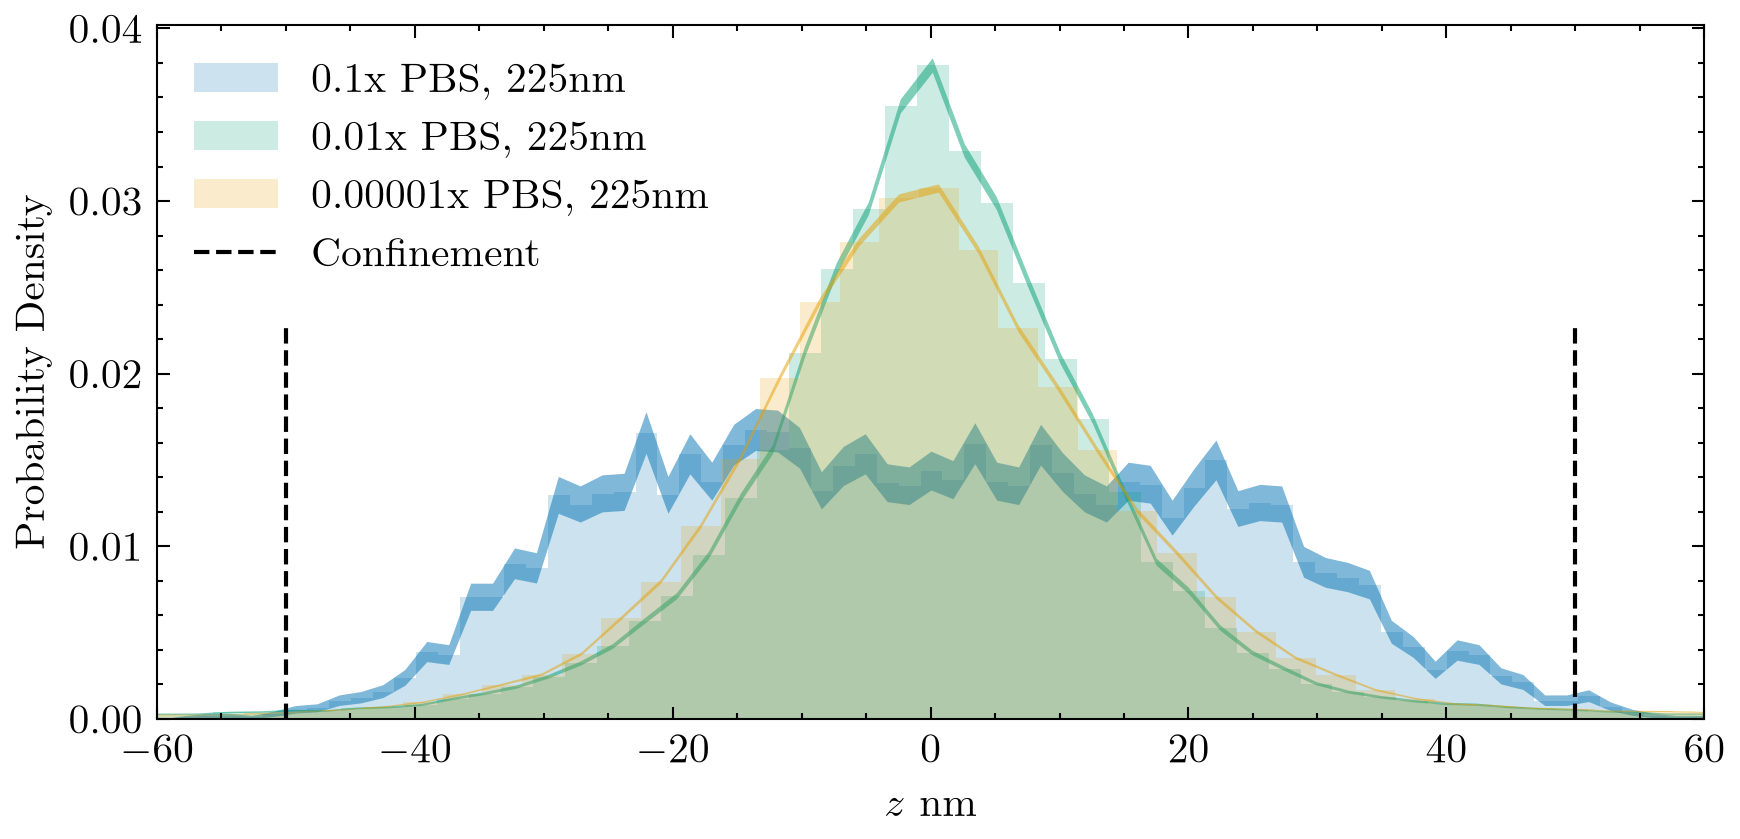

WindowsPath('Figures/Chapter7/c7_fig3.svg')

In [26]:
len_dataset = len(panel_b_datasets)


# construct figure body
fig = plt.figure(figsize=(6,3))
ax = fig.add_subplot()

PBS0p1_zdata         = np.concatenate(ensemble_hist[0], axis=0)
PBS0p01_zdata        = np.concatenate(ensemble_hist[1], axis=0)
PBS0p001_zdata       = np.concatenate(ensemble_hist[2], axis=0)
PBS0p00001_zdata     = np.concatenate(ensemble_hist[3], axis=0)


def PlotHistogram(data, ax0, label):
    counts, bins, _ = ax0.hist(data,   bins=100,  density=True, alpha=0.2, label=label)
    centers  = (bins[:-1] + bins[1:])/2
    dx = np.diff(bins)
    N = len(data)
    std = np.sqrt(counts / (N * dx))
    ax.fill_between(centers , counts-std, counts+std, alpha=0.5)

    return counts, bins

counts_all = []


c1, b1 = PlotHistogram(PBS0p1_zdata,        ax, '0.1x  PBS, 225nm')
c2, b2 = PlotHistogram(PBS0p01_zdata,       ax, '0.01x  PBS, 225nm')
c4, b4 = PlotHistogram(PBS0p00001_zdata,    ax, '0.00001x  PBS, 225nm')

# counting
counts_all.append(c1)
counts_all.append(c2)
counts_all.append(c4)
max_y = np.array(counts_all).max()
ax.vlines(100- 50,  0, max_y - 0.015, 'black', 'dashed')
ax.vlines(-100+ 50, 0, max_y - 0.015, 'black', 'dashed', label='Confinement')
ax.set_xlim(-110 + 50, 110 - 50)

ax.set_xlabel(r'$z$ nm')
ax.set_ylabel(r'Probability Density')

plt.legend(loc='upper left')
plt.tight_layout()
plt.show()


save_fig(fig, 'Figures/Chapter7/c7_fig3', also='pdf')